# ENVIRONMENT CONFIGURATION

In [2]:
import os
import sys
import json
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None  # Prevent DecompressionBombError on large images

import csv
import yaml
from collections import Counter, defaultdict

import torch

In [ ]:
# ==========================================================
# RT-DETR Repository Download
# ==========================================================

SCRIPT_DIR = Path.cwd()
RTDETR_REPO_DIR = SCRIPT_DIR / "RT_DETR" / "rtdetrv2_pytorch"
if not RTDETR_REPO_DIR.exists():
    parent_repo = SCRIPT_DIR.parent / "RT_DETR" / "rtdetrv2_pytorch"
    if parent_repo.exists():
        RTDETR_REPO_DIR = parent_repo
    else:
        print("Cloning RT-DETR repository...")
        import subprocess
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git", str(SCRIPT_DIR / "RT_DETR")], check=True)

if str(RTDETR_REPO_DIR) not in sys.path:
    sys.path.insert(0, str(RTDETR_REPO_DIR))

# Import official RT-DETR modules and helper loader
from load_rtdetr import load_rtdetr, MODELS, SIZE_ALIASES, REPO_PATH
from src.core import YAMLConfig
from src.core.yaml_utils import load_config
from src.solver import TASKS
from src.misc import dist_utils

In [4]:
# ==========================================================
# 1. RANDOMNESS AND TRAINING SEED
# ==========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_random(seed=SEED):
    """Get a Python Random instance with a given seed. Default to global seed."""
    return random.Random(seed)

set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [23]:
# ==========================================================
# 2. ACCELERATED DEVICE DETECTION
# ==========================================================
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0")
    device_desc = f"NVIDIA GPU ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    device_desc = "Apple Silicon GPU (MPS)"
else:
    DEVICE = torch.device("cpu")
    device_desc = "CPU"

print(f"OS platform: {os.name}")
print("CPU Model: Intel i7-10700")
print(f"CPU name: {os.uname().sysname} {os.uname().release} {os.uname().version}")
print(f"CPU cores: {os.cpu_count()}")
print(f"RAM: {round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / (1024 ** 3), 2)} GB")
print(f"Python version: {sys.version}")
print(f"PyTorch version: {torch.__version__}")
print(f"OpenCV version:  {cv2.__version__}")
print(f"RT-DETR backend loaded from: {RTDETR_REPO_DIR}")
print(f"Using device:    {DEVICE} ({device_desc})")
print(f"VRAM available: {round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2) if torch.cuda.is_available() else 'N/A'} GB")

OS platform: posix
CPU Model: Intel i7-10700
CPU name: Linux 7.3.3-1-cachyos #1 SMP PREEMPT_DYNAMIC Sat, 07 Nov 2026 13:54:44 +0000
CPU cores: 16
RAM: 31.25 GB
Python version: 3.11.8 (main, Feb 25 2024, 04:18:18) [Clang 17.0.6 ]
PyTorch version: 2.6.0+cu124
OpenCV version:  4.10.0
RT-DETR backend loaded from: /home/skinnydevi/Development/computer-vision/P4/P4a/RT_DETR/rtdetrv2_pytorch
Using device:    cuda:0 (NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti))
VRAM available: 7.67 GB


# DATASET LOADERS AND PREVIEW

In [24]:
class LicensePlateDatasetLoader:
    """
    Loader and inspector for license plate datasets for training.
    Tests for 1:1 image:annotation files, normalizes data for detection training.
    """
    VALID_EXTS = {'.jpg', '.jpeg'}

    def __init__(self, dataset_path):
        self.dataset_path = Path(dataset_path).resolve()
        self.images_dir = self.dataset_path / "images"
        self.annotations_dir = self.dataset_path / "annotations"
        
        if not self.images_dir.exists():
            raise FileNotFoundError(f"Images folder not found for dataset: {self.images_dir}")
        if not self.annotations_dir.exists():
            raise FileNotFoundError(f"Annotations folder not found for dataset: {self.annotations_dir}")

        self.samples = []
        self.integrity_report = {}

    def _get_image_dimensions(self, img_path):
        """Read (width, height) of image using OpenCV or Pillow"""
        
        try:
            with Image.open(img_path) as im:
                return im.size  # (width, height)
        except Exception:
            img = cv2.imread(str(img_path))
            
            if img is not None:
                h, w = img.shape[:2]
                return w, h
            
        return None, None

    def load_and_verify(self):
        """
        Scan dataset, match images with annotations, validate bboxes and report statistics.
        """
        print(f"Using dataset in: {self.dataset_path}")
        
        all_img_files = [f for f in self.images_dir.iterdir() if f.suffix.lower() in self.VALID_EXTS]
        all_ann_files = {f.stem: f for f in self.annotations_dir.iterdir() if f.suffix.lower() == '.json'}

        missing_annotations = []
        corrupted_annotations = []
        samples = []
        pixel_coords_converted = 0
        total_boxes = 0

        for img_path in sorted(all_img_files, key=lambda p:p.name):
            stem = img_path.stem
            ann_path = all_ann_files.get(stem)
            
            # Annotation does not exists
            if ann_path is None or not ann_path.exists():
                missing_annotations.append(stem)
                continue

            try:
                with open(ann_path, "r", encoding="utf-8") as f:
                    ann_data = json.load(f)
            except Exception as e:
                # JSON is malformed
                corrupted_annotations.append((stem, str(e)))
                continue

            # No list of rectangles in annotation
            if not isinstance(ann_data, list):
                corrupted_annotations.append((stem, "JSON root is not a list"))
                continue

            img_w, img_h = None, None
            boxes = []
            plates = []
            for item in ann_data:
                rect = item.get("rectangle")
                plate = item.get("plate", "None")
                if not rect or len(rect) != 4:
                    continue
                
                cx, cy, w, h = [float(v) for v in rect]
                
                if img_w is None or img_h is None:
                    img_w, img_h = self._get_image_dimensions(img_path)
                
                # If no read dimensions, skip = invalid
                if img_w is None or img_h is None:
                    continue
                
                # Normalize coordinates if annotation is in pixels
                if cx > 1.05 or cy > 1.05 or w > 1.05 or h > 1.05:
                    w_px = w
                    h_px = h
                    cx = cx / img_w
                    cy = cy / img_h
                    w = w / img_w
                    h = h / img_h
                    pixel_coords_converted += 1
                else:
                    w_px = w * img_w
                    h_px = h * img_h
                
                # Normalization clipping
                x_min = max(0.0, cx - w / 2.0)
                x_max = min(1.0, cx + w / 2.0)
                y_min = max(0.0, cy - h / 2.0)
                y_max = min(1.0, cy + h / 2.0)
                
                cx = (x_min + x_max) / 2.0
                cy = (y_min + y_max) / 2.0
                w = x_max - x_min
                h = y_max - y_min

                # Get real camera aspect ratio
                aspect_ratio_real = w_px / max(h_px, 1e-6)

                # Discard any really vertical annotation box or distorted
                if aspect_ratio_real < 0.95:
                    continue

                # Discard really small bboxes (noise)
                if h_px < 6 or w_px < 12:
                    continue
                
                if w > 0 and h > 0:
                    boxes.append([cx, cy, w, h])
                    plates.append(str(plate))
                    total_boxes += 1

            samples.append({
                "stem": stem,
                "image_path": img_path,
                "annotation_path": ann_path,
                "boxes": boxes, # list[cx, cy, w, h], normalized
                "plates": plates,
                "num_boxes": len(boxes),
                "width": img_w,
                "height": img_h,
            })

        self.samples = samples
        self.integrity_report = {
            "total_images_found": len(all_img_files),
            "total_annotations_found": len(all_ann_files),
            "valid_paired_samples": len(samples),
            "missing_annotations_count": len(missing_annotations),
            "missing_annotations_list": missing_annotations,
            "corrupted_annotations_count": len(corrupted_annotations),
            "corrupted_annotations_list": corrupted_annotations,
            "total_bounding_boxes": total_boxes,
            "boxes_converted_from_pixels": pixel_coords_converted
        }
        
        return self.integrity_report

    def print_summary(self):
        """Print all loaded dataset information"""
        
        rep = self.integrity_report
        print("=" * 60)
        print(" DATASET INTEGRITY REPORT")
        print("=" * 60)
        print(f"* Total images: {rep['total_images_found']}")
        print(f"* Total JSON annotations: {rep['total_annotations_found']}")
        print(f"* Correctly paired samples: {rep['valid_paired_samples']}")
        print(f"* Images with missing annotations: {rep['missing_annotations_count']}")
        print(f"* Invalid annotations: {rep['corrupted_annotations_count']}")
        print(f"* Total bounding boxes: {rep['total_bounding_boxes']}")
        print(f"* Normalized bounding boxes: {rep['boxes_converted_from_pixels']}")
        
        if rep['missing_annotations_count'] == 0:
            print("\n-> Every image has its corresponding annotation.")
        else:
            print(f"\n-> [WARNING] {rep['missing_annotations_count']} images don't have annotations.")
        print("=" * 60)

    def get_annotation_count(self, img_path):
        """Get registered bounding boxes for the image sample"""
        
        stem = Path(img_path).stem
        for sample in self.samples:
            if sample["stem"] == stem:
                return sample["num_boxes"]
        
        print("Couldn't get annotation count for ", img_path, "defaulting count to 0.")
        return 0

In [25]:
def resolve_dataset_path():
    dataset_paths = [
        Path("../../image-dataset/prac4VC_dataset"),
        Path("../../image-dataset/my-image-dataset"),
        Path("../image-dataset/my-image-dataset"),
        Path("../image-dataset/prac4VC_dataset"),
        Path("image-dataset/prac4VC_dataset"),
    ]
    
    for path in dataset_paths:
        if path.exists():
            print(f"Found dataset in path: {path.resolve()}")
            return path.resolve()
        else:
            print(f"Dataset not found in: {path}")

    raise FileNotFoundError("No valid dataset path was given.")

dataset_dir = resolve_dataset_path()
loader = LicensePlateDatasetLoader(dataset_dir)
report = loader.load_and_verify()
loader.print_summary()

Found dataset in path: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
Using dataset in: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
 DATASET INTEGRITY REPORT
* Total images: 2406
* Total JSON annotations: 2406
* Correctly paired samples: 2406
* Images with missing annotations: 0
* Invalid annotations: 0
* Total bounding boxes: 4371
* Normalized bounding boxes: 0

-> Every image has its corresponding annotation.


In [27]:
def prepare_rtdetr_dataset(samples, output_dir, split_ratios:tuple[float,float,float]=(0.75, 0.15, 0.10), seed=SEED, expected_img_size=640):
    """
    Splits the dataset into train, val, and test splits and formats them into
    the COCO dataset structure expected natively by RT-DETR (FasterCocoDetection).
    
    Optionally pre-resizes all images to `expected_img_size` (e.g. 640x640) and saves them
    into `output_dir / "image"` on disk, eliminating CPU JPEG decompression overhead during training.
    """
    
    from concurrent.futures import ThreadPoolExecutor
    from PIL import Image
    Image.MAX_IMAGE_PIXELS = None

    train_r, val_r, test_r = split_ratios
    assert abs(train_r + val_r + test_r - 1.0) < 1e-5, "Data split ratios sum should equal 1.0"

    output_path = Path(output_dir).resolve()
    ann_dir = output_path / "annotations"
    ann_dir.mkdir(parents=True, exist_ok=True)

    # Determine target dimensions if expected_img_size is provided
    if expected_img_size is not None:
        if isinstance(expected_img_size, (int, float)):
            target_w = target_h = int(expected_img_size)
        elif isinstance(expected_img_size, (tuple, list)) and len(expected_img_size) >= 2:
            target_w, target_h = int(expected_img_size[0]), int(expected_img_size[1])
        else:
            target_w = target_h = 640
    else:
        target_w = target_h = None

    image_dir = output_path / "images"
    if target_w is not None and target_h is not None:
        image_dir.mkdir(parents=True, exist_ok=True)
        # Create 'images' alias symlink if it doesn't already exist for backwards compatibility
        images_alias = output_path / "images_simlink"
        if not images_alias.exists():
            try:
                images_alias.symlink_to("images", target_is_directory=True)
            except Exception:
                pass

        # Identify unique images that need resizing
        unique_samples = {sample["image_path"]: sample for sample in samples}.values()
        to_resize = []
        for sample in unique_samples:
            dst_img = image_dir / sample["image_path"].name
            if not dst_img.exists() or dst_img.stat().st_size == 0:
                to_resize.append((sample["image_path"], dst_img))
        
        if to_resize:
            # Delete any existing images in the output directory to avoid stale files
            for existing_img in image_dir.iterdir():
                if existing_img.is_file() and existing_img.suffix.lower() in {'.jpg', '.jpeg'}:
                    try:
                        existing_img.unlink()
                    except Exception:
                        pass
            
            print(f"- Pre-resizing {len(to_resize)}/{len(unique_samples)} images to ({target_w}x{target_h}) in {image_dir}...")
            def _resize_single(task):
                src_path, dst_path = task
                try:
                    img = cv2.imread(str(src_path))
                    if img is not None:
                        resized = cv2.resize(img, (target_w, target_h), interpolation=cv2.INTER_LINEAR)
                        cv2.imwrite(str(dst_path), resized, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
                        return True
                except Exception:
                    pass
                
                # Fallback to Pillow
                try:
                    with Image.open(src_path) as pil_im:
                        pil_im = pil_im.convert("RGB")
                        resized = pil_im.resize((target_w, target_h), Image.Resampling.BILINEAR)
                        resized.save(dst_path, quality=98)
                        return True
                except Exception as e:
                    print(f"Warning: Failed to resize {src_path}: {e}")
                    return False

            with ThreadPoolExecutor(max_workers=8) as executor:
                list(executor.map(_resize_single, to_resize))
                
            print(f"  * Pre-resizing complete! Saved to {image_dir}")
            images_alias.unlink(missing_ok=True)
        else:
            print(f"- All {len(unique_samples)} images already pre-resized in {image_dir}")

    # Get random samples
    shuffled = list(samples)
    rnd = get_random(seed)
    rnd.shuffle(shuffled)

    n_samples = len(shuffled)
    n_train = int(n_samples * train_r)
    n_val = int(n_samples * val_r)

    split_dict = {
        "train": shuffled[:n_train],
        "val": shuffled[n_train:n_train + n_val],
        "test": shuffled[n_train + n_val:],
    }

    print(f"Splitting {n_samples} samples:")
    print(f"  * Train: {len(split_dict['train'])} ({train_r * 100:.1f}%)")
    print(f"  * Val:   {len(split_dict['val'])} ({val_r * 100:.1f}%)")
    print(f"  * Test:  {len(split_dict['test'])} ({test_r * 100:.1f}%)")

    dataset_paths = {}

    for split, split_samples in split_dict.items():
        coco_images = []
        coco_annotations = []
        ann_id = 0

        # Generate COCO format annotations for each split
        for img_id, sample in enumerate(split_samples):
            src_img = sample["image_path"]

            if target_w is not None and target_h is not None:
                w = target_w
                h = target_h
                img_folder_for_split = image_dir
            else:
                w = sample["width"] or 1920
                h = sample["height"] or 1080
                img_folder_for_split = sample["image_path"].parent

            coco_images.append({
                "id": img_id,
                "file_name": src_img.name,
                "width": int(w),
                "height": int(h),
            })

            # Convert YOLO normalized cxcywh to COCO absolute pixel [x, y, width, height]
            for box in sample["boxes"]:
                cx, cy, bw, bh = box
                x1 = round((cx - bw / 2.0) * w, 2)
                y1 = round((cy - bh / 2.0) * h, 2)
                box_w = round(bw * w, 2)
                box_h = round(bh * h, 2)
                area = round(box_w * box_h, 2)

                coco_annotations.append({
                    "id": ann_id,
                    "image_id": img_id,
                    "category_id": 0,  # 0: license_plate (single class)
                    "bbox": [x1, y1, box_w, box_h],
                    "area": area,
                    "iscrowd": 0,
                })
                ann_id += 1

        coco_data = {
            "images": coco_images,
            "annotations": coco_annotations,
            "categories": [{"id": 0, "name": "license_plate"}],
        }

        ann_file = ann_dir / f"instances_{split}.json"
        with open(ann_file, "w", encoding="utf-8") as f:
            json.dump(coco_data, f)

        dataset_paths[f"{split}_img"] = img_folder_for_split
        dataset_paths[f"{split}_ann"] = ann_file
        print(f"  * Split '{split}': {len(coco_images)} images, {len(coco_annotations)} boxes written to {ann_file.name}")

    print(f"- RT-DETR COCO format annotations generated at: {ann_dir}")
    print(f"- RT-DETR images directory: {dataset_paths['train_img']}")
    return dataset_paths, split_dict

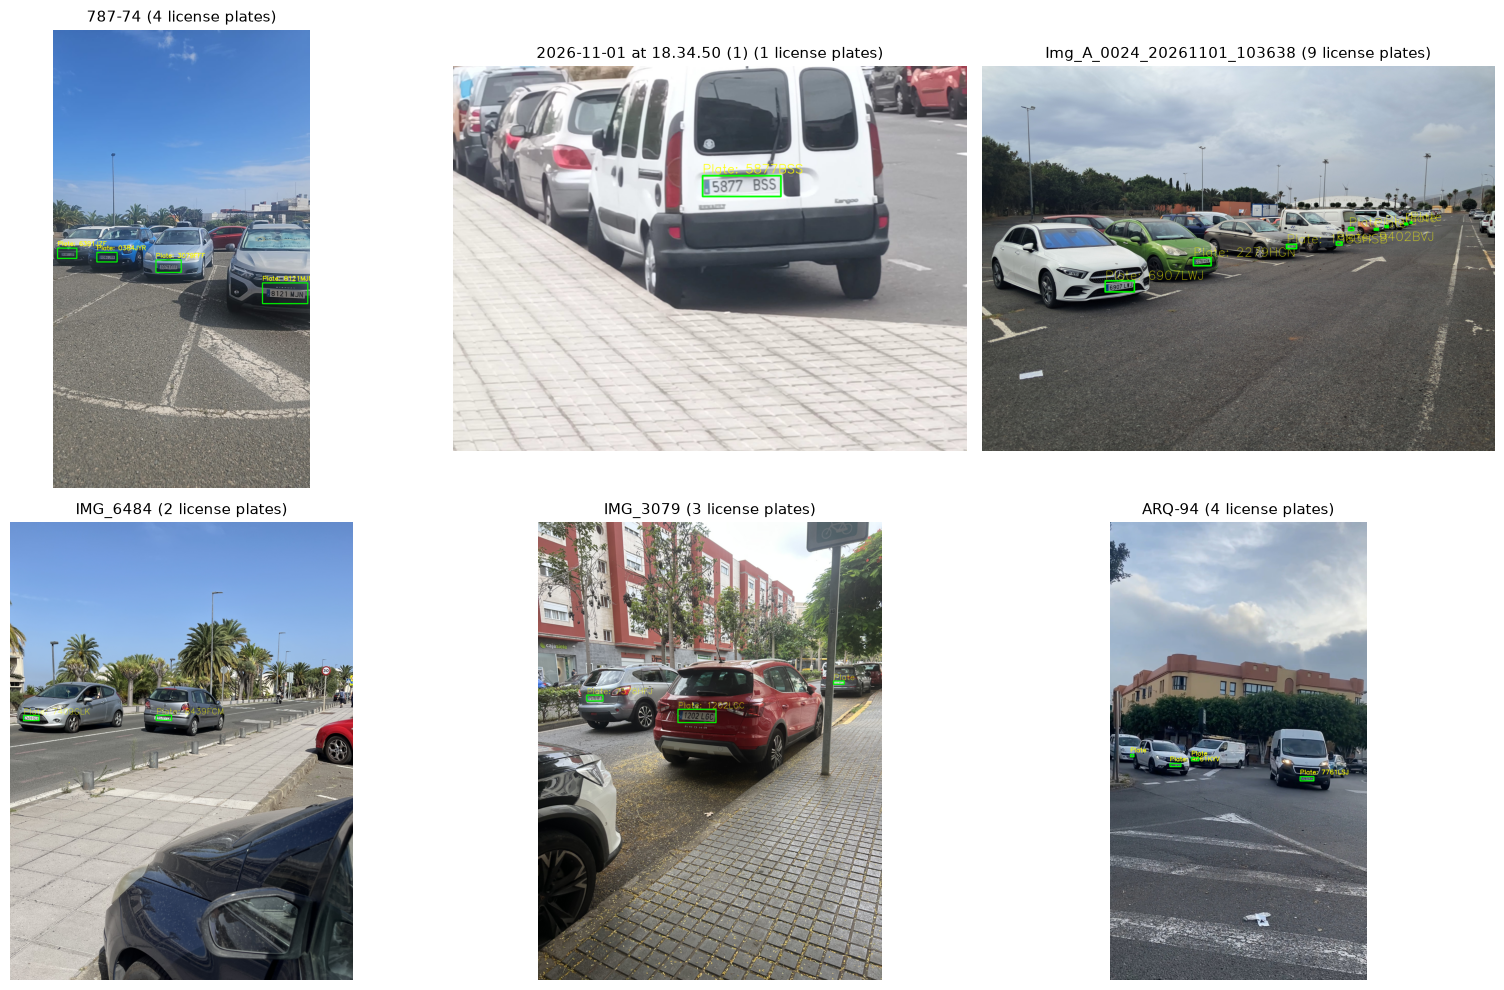

In [8]:
def visualize_dataset_samples(samples, num_samples=6, seed=SEED):
    """Show a grid of samples from a loaded dataset."""
    rndm_seed = get_random(seed)
    candidates = [s for s in samples if s["num_boxes"] > 0]  # At least 1 plate found
    selected = rndm_seed.sample(candidates, min(num_samples, len(candidates)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_bgr = cv2.imread(str(sample["image_path"]))
        if img_bgr is None:
            continue
        
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        for box, plate in zip(sample["boxes"], sample["plates"]):
            cx, cy, bw, bh = box
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)

            # Detection bbox in green
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), max(2, int(w * 0.003)))
            # Plate text
            label = f"Plate: {plate}" if plate != "None" else "Plate"
            cv2.putText(img_rgb, label, (x1, max(y1 - 10, 25)),
                        cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w * 0.0008), (255, 255, 0), 2)

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"{sample['stem']} ({sample['num_boxes']} license plates)", fontsize=11)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

visualize_dataset_samples(loader.samples, num_samples=6, seed=SEED)

In [15]:
IMGSZ = 960

In [28]:
rtdetr_dataset_dir = (dataset_dir.absolute() / Path(f"rtdetr-training_{IMGSZ}")).resolve()

dataset_paths, dataset_splits = prepare_rtdetr_dataset(
    samples=loader.samples,
    output_dir=rtdetr_dataset_dir,
    split_ratios=(0.75, 0.15, 0.10),
    seed=SEED,
    expected_img_size=IMGSZ
)

- All 2406 images already pre-resized in /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/rtdetr-training_960/images
Splitting 2406 samples:
  * Train: 1804 (75.0%)
  * Val:   360 (15.0%)
  * Test:  242 (10.0%)
  * Split 'train': 1804 images, 3243 boxes written to instances_train.json
  * Split 'val': 360 images, 681 boxes written to instances_val.json
  * Split 'test': 242 images, 447 boxes written to instances_test.json
- RT-DETR COCO format annotations generated at: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/rtdetr-training_960/annotations
- RT-DETR images directory: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/rtdetr-training_960/images


# RT-DETR TRAINING
We train the RT-DETR model using transfer learning. Pre-trained COCO weights are loaded,
the classification head is adapted for 1 class (license plate), and training is executed
via RT-DETR's solver engine.

In [18]:
SKIP_TRAINING = True
SKIP_TESTING = True

# Available model sizes in RT-DETRv2 (and v1)
AVAILABLE_MODELS = {
    "small":  {"family": "v2", "size": "s"},   # RT-DETRv2-S (ResNet-18vd)
    "medium": {"family": "v2", "size": "m"},   # RT-DETRv2-M (ResNet-50vd-m)
    "large":  {"family": "v2", "size": "l"},   # RT-DETRv2-L (ResNet-50vd)
    "xlarge": {"family": "v2", "size": "x"},   # RT-DETRv2-X (ResNet-101vd)
}

CHOSEN_MODEL_TYPE = "small"
model_info = AVAILABLE_MODELS[CHOSEN_MODEL_TYPE]
CHOSEN_FAMILY = model_info["family"]
CHOSEN_SIZE = model_info["size"]

print(f"Selected RT-DETR model: [{CHOSEN_MODEL_TYPE.upper()}] | Family: {CHOSEN_FAMILY} | Size: {CHOSEN_SIZE}")

# Load base model to verfy architecture and ensure weights are downloaded
base_model, base_postprocessor = load_rtdetr(family=CHOSEN_FAMILY, size=CHOSEN_SIZE, device=DEVICE)
print("* RT-DETR base model loaded successfully.")

Selected RT-DETR model: [SMALL] | Family: v2 | Size: s
Cargando RT-DETR familia 'v2', tamaño 'r18' en cuda:0
Load PResNet18 state_dict
* RT-DETR base model loaded successfully.


In [17]:
EPOCHS = 120
BATCH_SIZE = 8

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "runs").exists() and (NOTEBOOK_DIR / "P4" / "P4a" / "runs").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "P4" / "P4a"

PROJECT = (NOTEBOOK_DIR / "runs" / "detect" / "runs_plate").resolve()
EXPERIMENT_NAME = f"plate_detector_rtdetr_{CHOSEN_FAMILY}_{CHOSEN_SIZE}_{IMGSZ}_BATCH_{BATCH_SIZE}"
RUN_OUTPUT_DIR = PROJECT / EXPERIMENT_NAME
RUN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Resolve base configuration file and downloaded pre-trained weights
size_key = SIZE_ALIASES.get(CHOSEN_SIZE, CHOSEN_SIZE)
base_cfg_rel, release_tag, weight_file = MODELS[CHOSEN_FAMILY][size_key]
base_config_path = (REPO_PATH / "configs" / base_cfg_rel).resolve()
pretrained_weights_path = (SCRIPT_DIR / "rtdetr" / weight_file).resolve()
if not pretrained_weights_path.exists():
    pretrained_weights_path = (SCRIPT_DIR / "weights" / weight_file).resolve()

print(f"Training RT-DETR on device: {device_desc}")
print(f"Base Config:  {base_config_path}")
print(f"Pretrained:   {pretrained_weights_path}")
print(f"Epochs: {EPOCHS} | Batch Size: {BATCH_SIZE} | Image Size: {IMGSZ}x{IMGSZ}")
print(f"Output dir:   {RUN_OUTPUT_DIR}")

Training RT-DETR on device: NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti)
Base Config:  /home/skinnydevi/Development/computer-vision/P4/P4a/RT_DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_120e_coco.yml
Pretrained:   /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth
Epochs: 120 | Batch Size: 8 | Image Size: 960x960
Output dir:   /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8


In [29]:
def build_rtdetr_training_config(
    base_config_path: Path,
    output_dir: Path,
    pretrained_weights: Path,
    dataset_paths: dict,
    epochs: int = 60,
    batch_size: int = 16,
    num_classes: int = 1,
    workers: int = 0,
    amp: bool = True,
    imgsize: int = 640,
    box_gain: float = 8.5,
    cls_gain: float = 1.5,
):
    """
    Creates a customized YAML configuration for fine-tuning RT-DETR on the custom dataset.
    Uses an efficient transform pipeline that resizes images directly to 640x640,
    preventing PIL DecompressionBombError on high-res images and eliminating GPU OOM.
    """
    
    config_dict = {
        "__include__": [str(base_config_path.as_posix())],
        "output_dir": str(output_dir.as_posix()),
        "num_classes": num_classes,
        "remap_mscoco_category": False,
        "tuning": str(pretrained_weights.as_posix()),
        "epoches": epochs,
        "print_freq": 20,
        "checkpoint_freq": 10,
        "use_amp": amp,
        "eval_spatial_size": [imgsize, imgsize],
        "train_dataloader": {
            "dataset": {
                "img_folder": str(dataset_paths["train_img"].as_posix()),
                "ann_file": str(dataset_paths["train_ann"].as_posix()),
                "return_masks": False,
                "transforms": {
                    "type": "Compose",
                    "ops": [
                        {"type": "RandomPhotometricDistort", "p": 0.5},
                        {"type": "Resize", "size": [imgsize, imgsize]},
                        {"type": "RandomHorizontalFlip"},
                        {"type": "SanitizeBoundingBoxes", "min_size": 1},
                        {"type": "ConvertPILImage", "dtype": "float32", "scale": True},
                        {"type": "ConvertBoxes", "fmt": "cxcywh", "normalize": True},
                    ],
                },
            },
            "total_batch_size": batch_size,
            "num_workers": workers,
            "shuffle": True,
            "collate_fn": {
                "type": "BatchImageCollateFunction",
                "scales": None,
            },
        },
        "val_dataloader": {
            "dataset": {
                "img_folder": str(dataset_paths["val_img"].as_posix()),
                "ann_file": str(dataset_paths["val_ann"].as_posix()),
                "return_masks": False,
                "transforms": {
                    "type": "Compose",
                    "ops": [
                        {"type": "Resize", "size": [imgsize, imgsize]},
                        {"type": "ConvertPILImage", "dtype": "float32", "scale": True},
                    ],
                },
            },
            "total_batch_size": batch_size,
            "num_workers": 0,
            "shuffle": False,
        },
        "criterion": "RTDETRCriterionv2", # or RTDETRCriterionv2 for rtdetrv2 configs  
        "RTDETRCriterionv2": {
            "weight_dict": {  
                "loss_vfl": cls_gain,     # cls gain
                "loss_bbox": box_gain,    # box gain  
                "loss_giou": 2,
            },  
            "losses": ["vfl", "boxes"],  
            "alpha": 0.75,  # weight for focal loss
            "gamma": 2.0,   # focusing parameter for focal loss
            "matcher": {
                "type": "HungarianMatcher",  
                "weight_dict": {"cost_class": cls_gain, "cost_bbox": box_gain, "cost_giou": 2},  
                "alpha": 0.25,  
                "gamma": 2.0,  
            },  
        },
    }

    custom_cfg_file = output_dir / "custom_train_config.yml"
    with open(custom_cfg_file, "w", encoding="utf-8") as f:
        yaml.dump(config_dict, f, default_flow_style=False)

    return custom_cfg_file

custom_train_config_path = build_rtdetr_training_config(
    base_config_path=base_config_path,
    output_dir=RUN_OUTPUT_DIR,
    pretrained_weights=pretrained_weights_path,
    dataset_paths=dataset_paths,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    num_classes=1,
    workers=4,
    amp=True,
    imgsize=IMGSZ,
    box_gain=8.5,
    cls_gain=1.5
)
print(f"Generated RT-DETR training configuration: {custom_train_config_path}")

Generated RT-DETR training configuration: /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8/custom_train_config.yml


In [25]:
def plot_rtdetr_training_results(log_file: Path, save_path: Path):
    """
    Reads RT-DETR's log.txt (JSON Lines) and plots training losses and validation mAP curves.
    Saves the combined summary figure to results.png.
    """
    if not log_file.exists():
        print(f"No log file found at {log_file}")
        return

    epochs, total_losses, bbox_losses, giou_losses, vfl_losses = [], [], [], [], []
    map50_95, map50, map75 = [], [], []
    mar50_95, mar50, mar75 = [], [], []

    with open(log_file, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                data = json.loads(line)
            except Exception:
                continue

            ep = data.get("epoch", len(epochs))
            epochs.append(ep)
            total_losses.append(data.get("train_loss", 0.0))
            bbox_losses.append(data.get("train_loss_bbox", 0.0))
            giou_losses.append(data.get("train_loss_giou", 0.0))
            vfl_losses.append(data.get("train_loss_vfl", 0.0))

            test_bbox = data.get("test_coco_eval_bbox", [])
            if len(test_bbox) >= 3:
                map50_95.append(test_bbox[0])
                map50.append(test_bbox[1])
                map75.append(test_bbox[2])
                mar50_95.append(test_bbox[3])
                mar50.append(test_bbox[4])
                mar75.append(test_bbox[5])
            else:
                map50_95.append(0.0)
                map50.append(0.0)
                map75.append(0.0)
                mar50_95.append(0.0)
                mar50.append(0.0)
                mar75.append(0.0)

    if not epochs:
        print("Log file is empty or contains no parseable epoch data.")
        return

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    # Loss curves
    axes[0].plot(epochs, total_losses, label="Total Loss", color="#e74c3c", lw=2)
    axes[0].plot(epochs, bbox_losses, label="Bbox Loss", color="#3498db", lw=1.5)
    axes[0].plot(epochs, giou_losses, label="GIoU Loss", color="#2ecc71", lw=1.5)
    axes[0].plot(epochs, vfl_losses, label="VFL Loss", color="#9b59b6", lw=1.5)
    axes[0].set_title("RT-DETR Training Loss per Epoch", fontsize=12)
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()

    # mAP curves
    axes[1].plot(epochs, map50, label="mAP@50", color="#e67e22", lw=2)
    axes[1].plot(epochs, map50_95, label="mAP@50-95", color="#1abc9c", lw=2)
    axes[1].plot(epochs, map75, label="mAP@75", color="#34495e", lw=1.5, linestyle="--")
    axes[1].set_title("RT-DETR Validation mAP (COCO)", fontsize=12)
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AP Score")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend()
    
    # mAR curves (if available)
    axes[2].plot(epochs, mar50, label="mAR@50", color="#f39c12", lw=1.5, linestyle=":")
    axes[2].plot(epochs, mar50_95, label="mAR@50-95", color="#8e44ad", lw=1.5, linestyle=":")
    axes[2].plot(epochs, mar75, label="mAR@75", color="#2c3e50", lw=1.5, linestyle=":")
    axes[2].set_title("RT-DETR Validation mAP/mAR (COCO)", fontsize=12)
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("AR Score")
    axes[2].grid(True, linestyle="--", alpha=0.5)
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(str(save_path), dpi=200)
    plt.close()
    print(f"Training metrics plot saved to: {save_path}")


In [ ]:
if not SKIP_TRAINING:
    print("\n" + "=" * 60)
    print(" STARTING RT-DETR MODEL TRAINING")
    print("=" * 60)
    dist_utils.setup_distributed(seed=SEED)
    load_config.__defaults__[0].clear()

    train_cfg = YAMLConfig(
        str(custom_train_config_path),
        device=str(DEVICE),
        use_amp=(DEVICE.type == "cuda"),
        seed=SEED,
    )
    solver = TASKS[train_cfg.yaml_cfg["task"]](train_cfg)
    solver.fit()

    best_ckpt = RUN_OUTPUT_DIR / "best.pth"
    print("\nTraining finished! Best checkpoint saved at:", best_ckpt)
else:
    print("Training Skipped. Set SKIP_TRAINING = False to enable model training.")


 STARTING RT-DETR MODEL TRAINING
Not init distributed mode.
Start training
Load PResNet18 state_dict
tuning checkpoint from /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth
Load model.state_dict, {'missed': [], 'unmatched': ['decoder.anchors', 'decoder.valid_mask', 'decoder.denoising_class_embed.weight', 'decoder.enc_score_head.weight', 'decoder.enc_score_head.bias', 'decoder.dec_score_head.0.weight', 'decoder.dec_score_head.0.bias', 'decoder.dec_score_head.1.weight', 'decoder.dec_score_head.1.bias', 'decoder.dec_score_head.2.weight', 'decoder.dec_score_head.2.bias']}
Initial lr: [0.0001, 0.0001]
building train_dataloader with batch_size=8...
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
building val_dataloader with batch_size=8...
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
number of trainable parameters: 20083028


/home/skinnydevi/Development/computer-vision/P4/P4a/RT_DETR/rtdetrv2_pytorch/src/core/workspace.py:179: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  return module(**module_kwargs)


Epoch: [0]  [  0/225]  eta: 0:07:08  lr: 0.000000  loss: 27.3685 (27.3685)  loss_vfl: 0.5264 (0.5264)  loss_bbox: 1.3397 (1.3397)  loss_giou: 2.0230 (2.0230)  loss_vfl_aux_0: 0.3523 (0.3523)  loss_bbox_aux_0: 1.5910 (1.5910)  loss_giou_aux_0: 2.0857 (2.0857)  loss_vfl_aux_1: 0.3311 (0.3311)  loss_bbox_aux_1: 1.4243 (1.4243)  loss_giou_aux_1: 2.1635 (2.1635)  loss_vfl_dn_0: 0.7808 (0.7808)  loss_bbox_dn_0: 1.5654 (1.5654)  loss_giou_dn_0: 1.5624 (1.5624)  loss_vfl_dn_1: 0.7695 (0.7695)  loss_bbox_dn_1: 1.3944 (1.3944)  loss_giou_dn_1: 1.6054 (1.6054)  loss_vfl_dn_2: 0.8145 (0.8145)  loss_bbox_dn_2: 1.3465 (1.3465)  loss_giou_dn_2: 1.6409 (1.6409)  loss_vfl_enc_0: 0.2852 (0.2852)  loss_bbox_enc_0: 1.6131 (1.6131)  loss_giou_enc_0: 2.1535 (2.1535)  time: 1.9025  data: 0.7390  max mem: 5827
Epoch: [0]  [ 20/225]  eta: 0:01:42  lr: 0.000001  loss: 26.1890 (27.0138)  loss_vfl: 0.0936 (0.1626)  loss_bbox: 1.6281 (1.5873)  loss_giou: 2.5045 (2.4913)  loss_vfl_aux_0: 0.0759 (0.1287)  loss_bbox_

Training metrics plot saved to: /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8/results.png


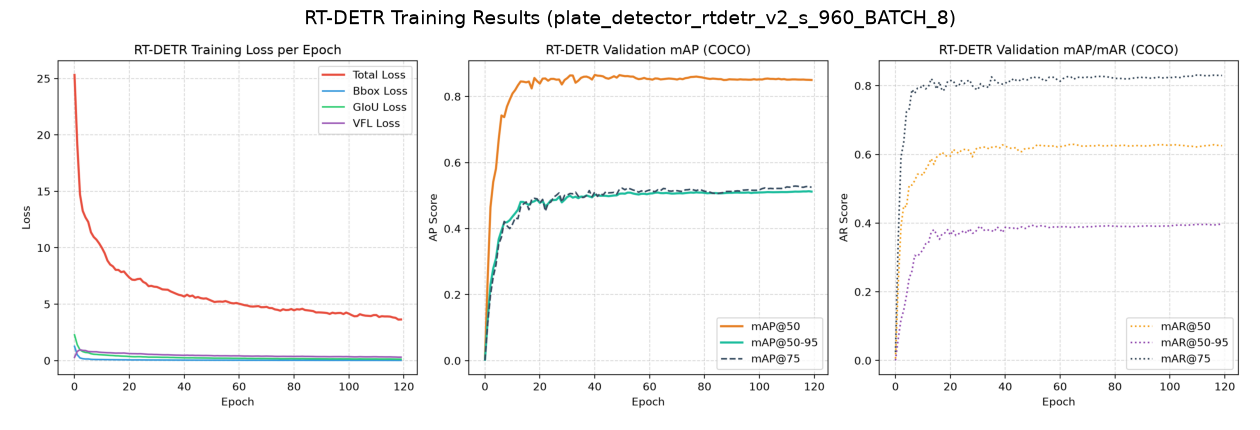

In [26]:
plot_rtdetr_training_results(RUN_OUTPUT_DIR / "log.txt", RUN_OUTPUT_DIR / "results.png")
results_img_path = RUN_OUTPUT_DIR / "results.png"
if results_img_path.exists():
    plt.figure(figsize=(16, 6))
    res_img = cv2.imread(str(results_img_path))
    res_img = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
    plt.imshow(res_img)
    plt.axis("off")
    plt.title(f"RT-DETR Training Results ({EXPERIMENT_NAME})", fontsize=14)
    plt.show()
else:
    print(f"No results image found at: {results_img_path}")

# RT-DETR TESTING AND EVALUATION
- **Precision / Recall (AR@100)**: Proporción de matrículas predichas y reales detectadas.
- **mAP@50**: Precisión media calculada con umbral IoU de $0.50$.
- **mAP@50-95**: Precisión media acumulada calculada para umbrales IoU entre $0.50$ y $0.95$ con paso $0.05$.

In [30]:
best_weights_path = RUN_OUTPUT_DIR / "best.pth"
if not best_weights_path.exists():
    print(f"WARNING: No checkpoint found at {best_weights_path}. Using base pre-trained model for testing.")
    trained_model = base_model
    trained_postprocessor = base_postprocessor
else:
    print(f"Loading best weights from: {best_weights_path}")
    trained_model, trained_postprocessor = load_rtdetr(
        family=CHOSEN_FAMILY,
        size=CHOSEN_SIZE,
        device=DEVICE,
        weights_path=best_weights_path,
        config_path=custom_train_config_path,
        num_classes=1,
    )

Loading best weights from: /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8/best.pth
Cargando RT-DETR desde checkpoint personalizado: /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8/best.pth en cuda:0
Load PResNet18 state_dict


In [32]:
if SKIP_TESTING:
    print("Testing skipped. Set SKIP_TESTING = False to enable evaluation on the test set.")
else:
    print("Evaluating RT-DETR on the TEST set...")
    from src.solver.det_engine import evaluate as rtdetr_evaluate
    
    # Create configuration for evaluating on the test split
    test_eval_config = {
        "__include__": [str(custom_train_config_path.as_posix())],
        "output_dir": str((RUN_OUTPUT_DIR / "test_eval").as_posix()),
        "val_dataloader": {
            "dataset": {
                "img_folder": str(dataset_paths["test_img"].as_posix()),
                "ann_file": str(dataset_paths["test_ann"].as_posix()),
            },
            "total_batch_size": BATCH_SIZE,
            "num_workers": 2,
            "shuffle": False,
        },
    }
    
    test_cfg_path = RUN_OUTPUT_DIR / "custom_test_config.yml"
    with open(test_cfg_path, "w", encoding="utf-8") as f:
        yaml.dump(test_eval_config, f)

    load_config.__defaults__[0].clear()
    test_cfg = YAMLConfig(
        str(test_cfg_path),
        device=str(DEVICE),
        resume=str(best_weights_path) if best_weights_path.exists() else None,
    )
    test_solver = TASKS[test_cfg.yaml_cfg["task"]](test_cfg)
    test_solver.eval()
    
    # Run COCO evaluation on the test dataloader
    eval_module = test_solver.ema.module if test_solver.ema else test_solver.model
    test_stats, coco_evaluator = rtdetr_evaluate(
        eval_module,
        test_solver.criterion,
        test_solver.postprocessor,
        test_solver.val_dataloader,
        test_solver.evaluator,
        test_solver.device,
    )

    bbox_stats = test_stats.get("coco_eval_bbox", [0.0] * 12)
    map50_95 = bbox_stats[0]
    map50 = bbox_stats[1]
    map75 = bbox_stats[2]
    recall_100 = bbox_stats[8]

    print("=" * 60)
    print(" RT-DETR DETECTION METRICS ON TEST SET")
    print("=" * 60)
    print(f"• Recall (AR@100):     {recall_100:.4f} ({recall_100 * 100:.2f}%)")
    print(f"• mAP@50:              {map50:.4f} ({map50 * 100:.2f}%)")
    print(f"• mAP@75:              {map75:.4f} ({map75 * 100:.2f}%)")
    print(f"• mAP@50-95:           {map50_95:.4f} ({map50_95 * 100:.2f}%)")
    print("=" * 60)

Evaluating RT-DETR on the TEST set...
Load PResNet18 state_dict
tuning checkpoint from /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth
Load model.state_dict, {'missed': [], 'unmatched': ['decoder.anchors', 'decoder.valid_mask', 'decoder.denoising_class_embed.weight', 'decoder.enc_score_head.weight', 'decoder.enc_score_head.bias', 'decoder.dec_score_head.0.weight', 'decoder.dec_score_head.0.bias', 'decoder.dec_score_head.1.weight', 'decoder.dec_score_head.1.bias', 'decoder.dec_score_head.2.weight', 'decoder.dec_score_head.2.bias']}
building val_dataloader with batch_size=8...
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Resume checkpoint from /home/skinnydevi/Development/computer-vision/P4/P4a/runs/detect/runs_plate/plate_detector_rtdetr_v2_s_960_BATCH_8/best.pth


/home/skinnydevi/Development/computer-vision/P4/P4a/RT_DETR/rtdetrv2_pytorch/src/core/workspace.py:179: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  return module(**module_kwargs)


Load last_epoch
Load model.state_dict
Load criterion.state_dict
Load postprocessor.state_dict
Load ema.state_dict
Load scaler.state_dict
Test:  [ 0/31]  eta: 0:00:36    time: 1.1739  data: 0.2892  max mem: 1539
Test:  [10/31]  eta: 0:00:06    time: 0.3210  data: 0.0396  max mem: 1546
Test:  [20/31]  eta: 0:00:03    time: 0.2342  data: 0.0138  max mem: 1546
Test:  [30/31]  eta: 0:00:00    time: 0.2227  data: 0.0126  max mem: 1546
Test: Total time: 0:00:08 (0.2582 s / it)
Averaged stats: 
Accumulating evaluation results...
COCOeval_opt.accumulate() finished...
DONE (t=0.01s).
IoU metric: bbox
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.531
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.865
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.558
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.437
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.643
 A

 LABEL SUMMARY 
* Detected: number of detections made by RT-DETR in the image
* Total:    number of bboxes in the dataset loader for the image (excluding invalid annotations)
* Real:     number of bboxes in the original annotation file for the image


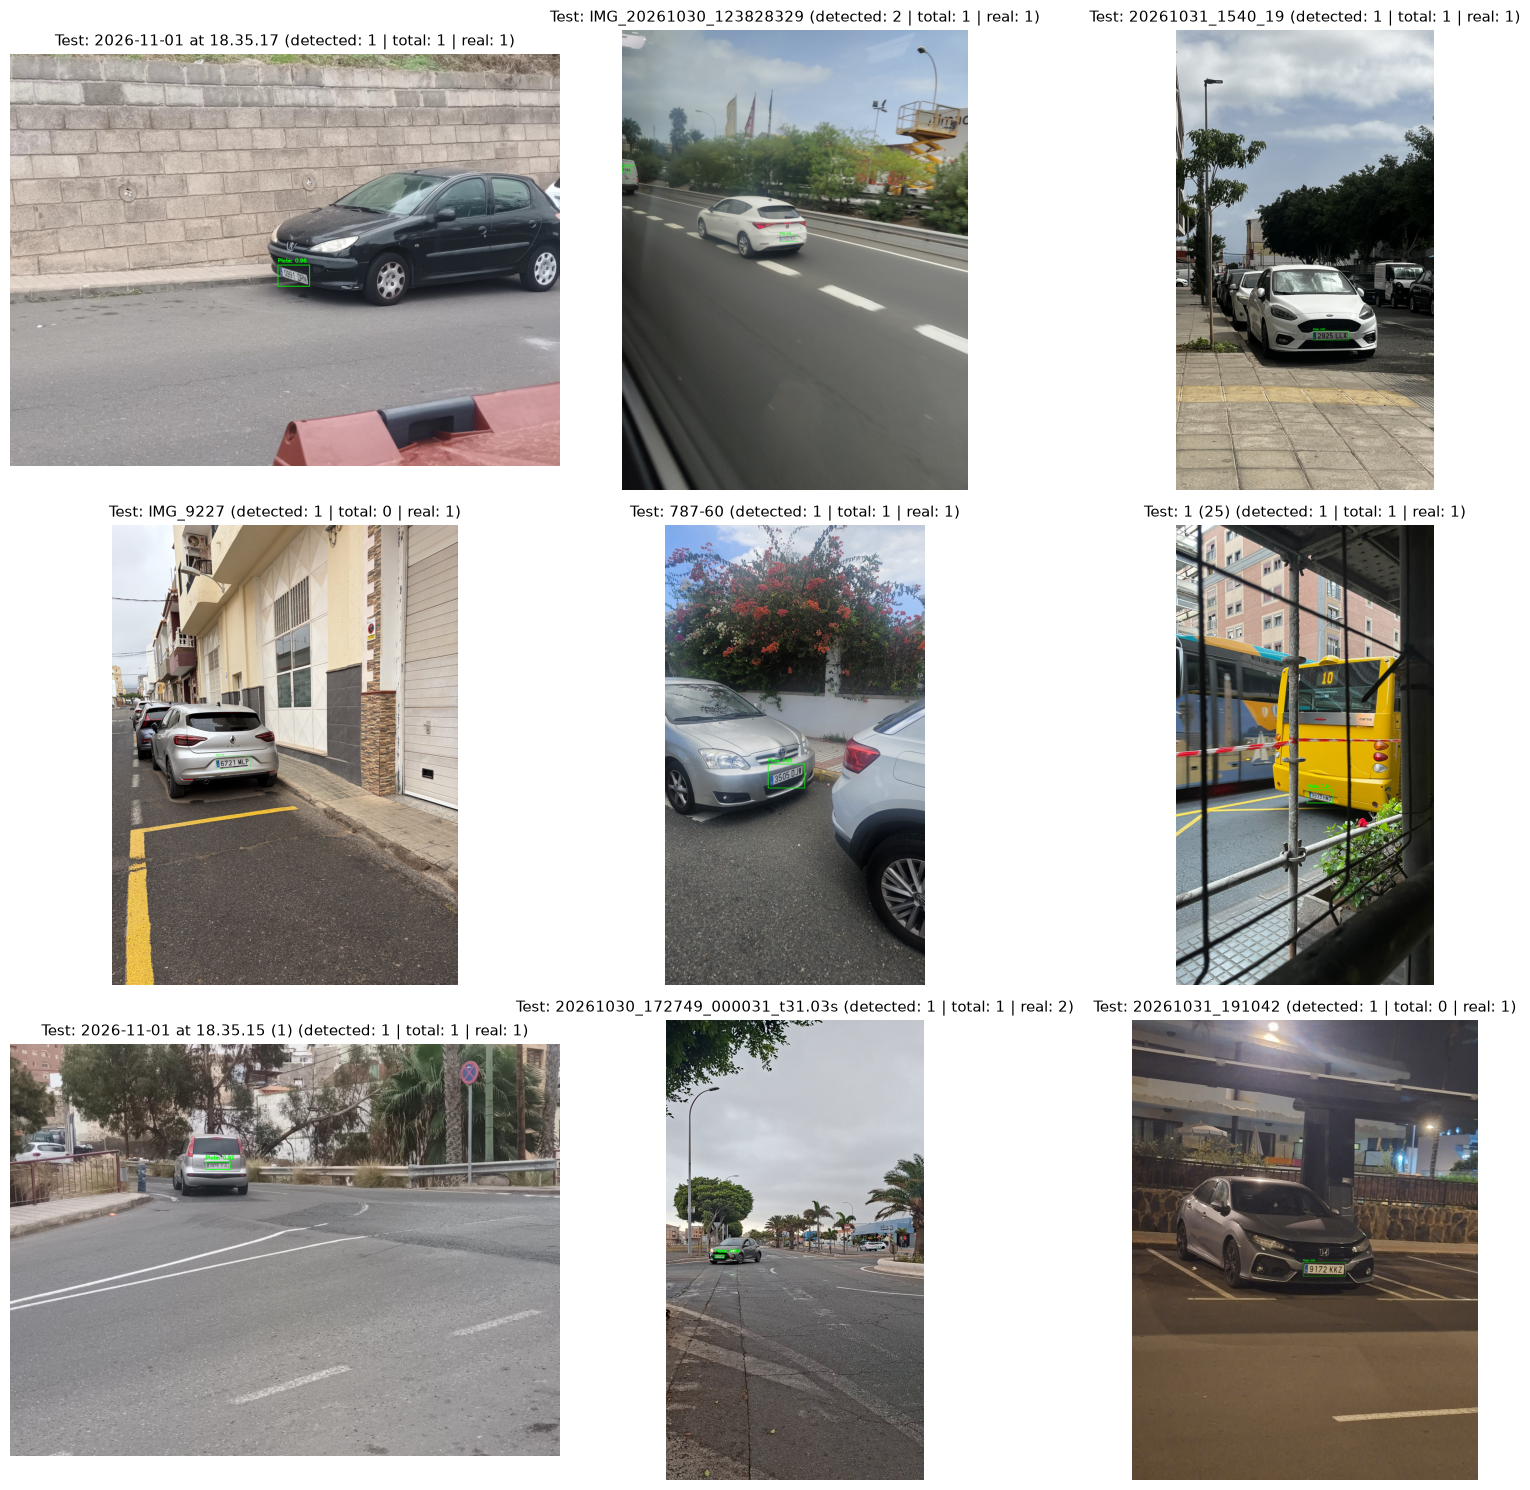

In [33]:
@torch.no_grad()
def rtdetr_detect(model, postprocessor, bgr_image, conf=0.35, device=DEVICE, imgsz=640):
    """
    Runs RT-DETR inference on a BGR image.
    Returns:
        boxes: np.ndarray of shape (N, 4) with coordinates [x1, y1, x2, y2]
        scores: np.ndarray of shape (N,) with confidence scores
        labels: np.ndarray of shape (N,) with class IDs
    """
    
    h, w = bgr_image.shape[:2]
    # Resize and convert BGR -> RGB -> Tensor
    im = Image.fromarray(cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)).resize((imgsz, imgsz), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(device)
    orig_sizes = torch.tensor([[w, h]], device=device)
    
    # Run inference and post-process detections
    labels, boxes, scores = postprocessor(model(x), orig_sizes)
    labels = labels[0].detach().cpu().numpy()
    boxes = boxes[0].detach().cpu().numpy()
    scores = scores[0].detach().cpu().numpy()

    keep = scores >= conf # Filter detections by confidence threshold
    return boxes[keep], scores[keep], labels[keep]

def get_sample_annotation_count(sample):
    """Get the number of original bounding boxes for a given sample."""
    
    ann_path = sample.get("annotation_path")
    if ann_path and Path(ann_path).exists():
        try:
            with open(ann_path, "r", encoding="utf-8") as f:
                ann_data = json.load(f)
            return len(ann_data) if isinstance(ann_data, list) else len(sample.get("boxes", []))
        except Exception:
            return len(sample.get("boxes", []))
        
    return sample.get("num_boxes", len(sample.get("boxes", [])))

def visualize_test_predictions(model, postprocessor, test_samples, num_samples=9, conf_threshold=0.35, seed=SEED):
    """
    Display predictions from the trained RT-DETR model on a random selection of test samples.
    """
    rndm_seed = get_random(seed)
    selected = rndm_seed.sample(test_samples, min(num_samples, len(test_samples)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_path = sample["image_path"]
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue

        boxes, scores, labels = rtdetr_detect(model, postprocessor, img_bgr, conf=conf_threshold, device=DEVICE, imgsz=IMGSZ)
        annotated_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        for box, score in zip(boxes, scores):
            x1, y1, x2, y2 = [int(v) for v in box]
            cv2.rectangle(annotated_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(
                annotated_rgb,
                f"Plate: {score:.2f}",
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2,
            )

        num_det = len(boxes)
        loader_count = loader.get_annotation_count(img_path)
        real_count = get_sample_annotation_count(sample)

        axes[i].imshow(annotated_rgb)
        axes[i].set_title(
            f"Test: {sample['stem']} (detected: {num_det} | total: {loader_count} | real: {real_count})",
            fontsize=11,
        )
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

rng_seed = random.Random()
rndm_seed = rng_seed.randint(0, 999999)
print(" LABEL SUMMARY ")
print("* Detected: number of detections made by RT-DETR in the image")
print("* Total:    number of bboxes in the dataset loader for the image (excluding invalid annotations)")
print("* Real:     number of bboxes in the original annotation file for the image")
visualize_test_predictions(trained_model, trained_postprocessor, dataset_splits["test"], num_samples=9, conf_threshold=0.35, seed=SEED)


# TESTING WITH VIDEO AND TRACKING
In this section, RT-DETR performs multi-class object detection and tracking for vehicles,
pedestrians, and license plates. Persistent tracking IDs are maintained across frames.

In [ ]:
from scipy.optimize import linear_sum_assignment

class BoxResult:
    """Wrapper matching the box API used downstream."""
    def __init__(self, xyxy, conf, cls, track_id=None):
        self.xyxy = torch.as_tensor(np.array([xyxy], dtype=np.float32))
        self.conf = torch.as_tensor([float(conf)], dtype=torch.float32)
        self.cls = torch.as_tensor([int(cls)], dtype=torch.int64)
        self.id = torch.as_tensor([int(track_id)], dtype=torch.int64) if track_id is not None else None

class DetectionResult:
    """Wrapper holding a list of detected BoxResults."""
    def __init__(self, boxes):
        self.boxes = boxes

    def __len__(self):
        return len(self.boxes)

class RTDETRTracker:
    """
    Multi-object tracker using IoU association and Hungarian matching.
    Provides persistent track IDs across video frames.
    """
    def __init__(self, max_lost_frames=45, iou_threshold=0.25):
        self.max_lost_frames = max_lost_frames
        self.iou_threshold = iou_threshold
        self.next_id = 1
        self.tracks = {}  # track_id -> {'box': [x1, y1, x2, y2], 'cls': int, 'lost': int, 'conf': float}

    @staticmethod
    def _compute_iou(boxes1, boxes2):
        """
        Compute the Intersection over Union (IoU) between two sets of boxes.
        """
        
        if len(boxes1) == 0 or len(boxes2) == 0:
            return np.zeros((len(boxes1), len(boxes2)))
        
        lt = np.maximum(boxes1[:, None, :2], boxes2[None, :, :2])
        rb = np.minimum(boxes1[:, None, 2:], boxes2[None, :, 2:])
        wh = np.clip(rb - lt, 0, None)
        inter = wh[:, :, 0] * wh[:, :, 1]
        area1 = (boxes1[:, 2] - boxes1[:, 0]) * (boxes1[:, 3] - boxes1[:, 1])
        area2 = (boxes2[:, 2] - boxes2[:, 0]) * (boxes2[:, 3] - boxes2[:, 1])
        union = area1[:, None] + area2[None, :] - inter
        return inter / np.clip(union, 1e-6, None)

    def update(self, det_boxes, det_scores, det_labels):
        """Update active tracks with new frame detections and return assigned IDs."""
        if len(det_boxes) == 0:
            # Increment lost counter for all active tracks
            to_del = []
            for tid in self.tracks:
                self.tracks[tid]['lost'] += 1
                if self.tracks[tid]['lost'] > self.max_lost_frames:
                    to_del.append(tid)
                    
            for tid in to_del:
                del self.tracks[tid]
            return []

        active_ids = list(self.tracks.keys())
        if len(active_ids) == 0:
            assigned = []
            for b, s, l in zip(det_boxes, det_scores, det_labels):
                tid = self.next_id
                self.next_id += 1
                self.tracks[tid] = {'box': b, 'cls': l, 'lost': 0, 'conf': s}
                assigned.append(tid)
            return assigned

        active_boxes = np.array([self.tracks[tid]['box'] for tid in active_ids])
        ious = self._compute_iou(active_boxes, det_boxes)

        row_ind, col_ind = linear_sum_assignment(-ious)
        assigned = [None] * len(det_boxes)
        matched_tracks = set()
        matched_dets = set()

        # Assign detections to tracks based on IoU threshold
        for row, col in zip(row_ind, col_ind):
            if ious[row, col] >= self.iou_threshold:
                tid = active_ids[row]
                assigned[col] = tid
                self.tracks[tid]['box'] = det_boxes[col]
                self.tracks[tid]['lost'] = 0
                self.tracks[tid]['conf'] = det_scores[col]
                matched_tracks.add(tid)
                matched_dets.add(col)

        # Unmatched active tracks
        to_del = []
        for tid in active_ids:
            if tid not in matched_tracks:
                self.tracks[tid]['lost'] += 1
                if self.tracks[tid]['lost'] > self.max_lost_frames:
                    to_del.append(tid)
                    
        for tid in to_del:
            del self.tracks[tid]

        # Unmatched detections -> new tracks
        for c in range(len(det_boxes)):
            if c not in matched_dets:
                tid = self.next_id
                self.next_id += 1
                self.tracks[tid] = {'box': det_boxes[c], 'cls': det_labels[c], 'lost': 0, 'conf': det_scores[c]}
                assigned[c] = tid

        return assigned

class RTDETRPredictor:
    """
    High-level interface for RT-DETR detection and tracking compatible
    with the video processing pipeline.
    """
    
    def __init__(self, model, postprocessor, device=DEVICE, imgsz=640):
        self.model = model
        self.postprocessor = postprocessor
        self.device = device
        self.imgsz = imgsz
        self.tracker = RTDETRTracker()

    def predict(self, frame, conf=0.35, classes=None):
        """
        Run RT-DETR detection on a single frame and return results in a structured format.
        """
        
        boxes, scores, labels = rtdetr_detect(
            self.model, self.postprocessor, frame, conf=conf, device=self.device, imgsz=self.imgsz
        )
        results = []
        for b, s, l in zip(boxes, scores, labels):
            if classes is not None and l not in classes:
                continue
            
            results.append(BoxResult(b, s, l, track_id=None))
            
        return [DetectionResult(results)]

    def track(self, frame, conf=0.35, classes=None, **kwargs):
        """
        Run RT-DETR tracking on a single frame and return results in a structured format.
        """
        boxes, scores, labels = rtdetr_detect(
            self.model, self.postprocessor, frame, conf=conf, device=self.device, imgsz=self.imgsz
        )
        
        # Filter by requested classes
        if classes is not None:
            mask = np.isin(labels, classes)
            boxes, scores, labels = boxes[mask], scores[mask], labels[mask]

        track_ids = self.tracker.update(boxes, scores, labels)
        results = []
        
        # Create BoxResult objects with assigned track IDs
        for b, s, l, tid in zip(boxes, scores, labels, track_ids):
            results.append(BoxResult(b, s, l, track_id=tid))
            
        return [DetectionResult(results)]

    def __call__(self, frame, conf=0.35, **kwargs):
        return self.predict(frame, conf=conf, **kwargs)

In [ ]:
class PedestrianOcclusionManager:
    """
    Manages the continuity of pedestrian identities when they suffer occlusions
    (e.g., when a vehicle passes in front of a person).
    """
    
    def __init__(self, max_gap_frames=90, max_distance=220, min_similarity=0.60):
        self.max_gap_frames = max_gap_frames
        self.max_distance = max_distance
        self.min_similarity = min_similarity
        
        self.id_remap = {}       # raw_id -> canonical_id
        self.lost_tracks = {}    # canonical_id -> dict with info of last known state
        self.active_tracks = {}  # canonical_id -> dict with last box and color histogram

    def resolve_id(self, raw_id):
        """
        Resolve a raw ID to its canonical ID.
        """
        
        curr = raw_id
        visited = set()
        while curr in self.id_remap and curr not in visited:
            visited.add(curr)
            curr = self.id_remap[curr]
            
        return curr

    @staticmethod
    def extract_color_hist(frame, box):
        """
        Extract a color histogram from a region of interest in the frame.
        """
        
        x1, y1, x2, y2 = box
        crop = frame[max(0, y1):max(0, y2), max(0, x1):max(0, x2)]
        if crop.size == 0 or crop.shape[0] < 6 or crop.shape[1] < 6:
            return None
        
        hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        hist = cv2.calcHist([hsv], [0, 1], None, [16, 16], [0, 180, 0, 256])
        cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
        return hist

    @staticmethod
    def get_center(box):
        return ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0)

    @staticmethod
    def compute_distance(p1, p2):
        """Euclidean distance between two points p1 and p2, where each point is (x, y)"""
        return ((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2) ** 0.5

    def _is_track_known(self, raw_id, canonical_id):
        return raw_id in self.id_remap or canonical_id in self.active_tracks

    def _check_lost_tracks(self, current_frame, p_center, p_hist):
        # If it's a new track we don't know created by RT-DETR
        best_match_id = None
        best_score = -1.0
        
        for lost_id, lost_info in list(self.lost_tracks.items()):
            # Check if the lost track is too old
            gap = current_frame - lost_info["last_frame"]
            if gap > self.max_gap_frames:
                continue
            
            # Check distance between last known position and current detection
            lost_center = self.get_center(lost_info["last_box"])
            dist = self.compute_distance(p_center, lost_center)
            max_allowed_dist = min(self.max_distance, 40.0 + gap * 3.5)
            if dist > max_allowed_dist:
                continue
            
            # HSV color histogram similarity (0.0 to 1.0, higher is more similar)
            similarity = 0.5
            if p_hist is not None and lost_info["color_hist"] is not None:
                similarity = cv2.compareHist(p_hist, lost_info["color_hist"], cv2.HISTCMP_CORREL)
            
            # If the lost track was occluded by a vehicle and reappears nearby, 
            # or if the similarity is high
            # 1200 = max distance in pixels for normalization
            score = similarity - (dist / 1200.0)
            if (similarity >= self.min_similarity) or (
                lost_info["occluded_by_vehicle"] and dist < 90 and similarity > 0.35
            ):
                if score > best_score:
                    best_score = score
                    best_match_id = lost_id
        
        return best_match_id, best_score

    def _relink_track(self, raw_id, best_match_id):
        self.id_remap[raw_id] = best_match_id
        if best_match_id in self.lost_tracks:
            del self.lost_tracks[best_match_id]
    
    def _update_active_track(self, canonical_id, p_box, p_hist, current_frame):
        self.active_tracks[canonical_id] = {
            "last_box": p_box,
            "color_hist": p_hist if p_hist is not None else self.active_tracks.get(canonical_id, {}).get("color_hist"),
            "last_frame": current_frame,
        }

    def _associate_or_link_pedestrian(self, raw_id, canonical_id, p_box, p_hist, current_frame):
        """
        Associate a detected pedestrian with an existing track or link it to a lost track.
        """
        
        if self._is_track_known(raw_id, canonical_id):
            self._update_active_track(canonical_id, p_box, p_hist, current_frame)
            return canonical_id

        p_center = self.get_center(p_box)
        best_match_id, _ = self._check_lost_tracks(current_frame, p_center, p_hist)
        
        if best_match_id is not None:
            self._relink_track(raw_id, best_match_id)
            canonical_id = best_match_id
        
        self._update_active_track(canonical_id, p_box, p_hist, current_frame)
        return canonical_id

    def _box_overlaps(self, b1, b2, iou_thresh=0.08):
        """
        Check if two bounding boxes overlap.
        """
        
        ix1 = max(b1[0], b2[0])
        iy1 = max(b1[1], b2[1])
        ix2 = min(b1[2], b2[2])
        iy2 = min(b1[3], b2[3])
        if ix1 >= ix2 or iy1 >= iy2:
            return False
        
        inter = (ix2 - ix1) * (iy2 - iy1)
        area1 = max(1, (b1[2] - b1[0]) * (b1[3] - b1[1]))
        return (inter / area1) >= iou_thresh

    def _process_missing_people_in_frame(self, current_canonical_ids, vehicle_boxes):
        """
        Get the missing pedestrians in the current frame and check if they are occluded by vehicles.
        """
        
        missing_ids = set(self.active_tracks.keys()) - current_canonical_ids
        for mid in missing_ids:
            track_info = self.active_tracks.pop(mid)
            occluded = any(self._box_overlaps(track_info["last_box"], vb) for vb in vehicle_boxes)
            self.lost_tracks[mid] = {
                **track_info,
                "occluded_by_vehicle": occluded,
            }

    def _cleanup_old_lost_tracks(self, current_frame):
        expired = [
            lid for lid, linfo in self.lost_tracks.items()
            if (current_frame - linfo["last_frame"]) > self.max_gap_frames
        ]
        
        for lid in expired:
            del self.lost_tracks[lid]

    def process_people_in_frame(self, frame, current_people, current_frame, vehicle_boxes):
        current_canonical_ids = set()
        for p in current_people:
            raw_id = p["track_id"]
            if raw_id == "":
                continue

            canonical_id = self.resolve_id(raw_id)
            p_hist = self.extract_color_hist(frame, p["box"])
            canonical_id = self._associate_or_link_pedestrian(raw_id, canonical_id, p["box"], p_hist, current_frame)
            p["track_id"] = canonical_id
            current_canonical_ids.add(canonical_id)

        self._process_missing_people_in_frame(current_canonical_ids, vehicle_boxes)
        self._cleanup_old_lost_tracks(current_frame)


In [ ]:
class LicensePlateVideoProcessor:
    """
    Processes a video to detect and track vehicles, license plates and pedestrians with RT-DETR.
    Applies occlusion management, hierarchical license plate memory and track class consensus.
    Saves the annotated video and generates the results CSV.
    """
    
    def __init__(
        self, 
        vehicle_model: RTDETRPredictor, 
        plate_model: RTDETRPredictor, 
        max_gap_frames=90, 
        max_distance=220,
        apply_censoring=False
    ):
        self.vehicle_model = vehicle_model
        self.plate_model = plate_model
        self.occlusion_manager = PedestrianOcclusionManager(
            max_gap_frames=max_gap_frames, 
            max_distance=max_distance
        )
        self.apply_censoring = apply_censoring
        
        self.video_width = None
        self.video_height = None
        self.video_fps = None
        self.video_total_frames = None
        
        # COCO class IDs for vehicles and people
        self.vehicle_classes = {
            0: "person",
            2: "car",
            3: "motorbike",
            5: "bus",
            # 7: "truck",
        }
        
        self.csv_columns = [
            "fotograma",
            "tipo_objeto",
            "confianza",
            "identificador_tracking",
            "x1",
            "y1",
            "x2",
            "y2",
            "matrícula_en_su_caso",
            "confianza",
            "mx1",
            "my1",
            "mx2",
            "my2",
            "texto_matricula",
        ]
        
        # Store the history of detected classes for each track ID
        self.track_class_history = defaultdict(lambda: Counter())
        self.confirmed_plates = set()
        self.raw_detection_counts = {name: 0 for name in self.vehicle_classes.values()}
        self.raw_detection_counts["license_plate"] = 0
        
    def box_values(self, box):
        """Extract bounding box coordinates, confidence and track ID."""
        
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
        confidence = float(box.conf[0])
        track_id = int(box.id[0]) if box.id is not None else ""
        
        return x1, y1, x2, y2, confidence, track_id
    
    def plate_belongs_to_vehicle(self, plate_box, vehicle_box):
        """Check if a license plate belongs to a detected vehicle based on spatial containment/overlap."""
        
        px1, py1, px2, py2 = plate_box
        vx1, vy1, vx2, vy2 = vehicle_box

        # Center test
        pcx = (px1 + px2) / 2.0
        pcy = (py1 + py2) / 2.0
        if vx1 <= pcx <= vx2 and vy1 <= pcy <= vy2:
            return True

        # Intersection area test (>= 50% plate area)
        ix1 = max(px1, vx1)
        iy1 = max(py1, vy1)
        ix2 = min(px2, vx2)
        iy2 = min(py2, vy2)
        if ix1 < ix2 and iy1 < iy2:
            inter_area = (ix2 - ix1) * (iy2 - iy1)
            plate_area = max(1, (px2 - px1) * (py2 - py1))
            if (inter_area / plate_area) >= 0.5:
                return True

        return False
    
    def _prepare_video_writer(self, input_video_path, output_video_path, max_frames=None):
        video_capture = cv2.VideoCapture(str(input_video_path))
        if not video_capture.isOpened():
            raise RuntimeError(f"Could not open video: {input_video_path}")
    
        self.video_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = video_capture.get(cv2.CAP_PROP_FPS) or 25.0
        self.video_total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))
    
        if max_frames is not None:
            self.video_total_frames = min(self.video_total_frames, max_frames)
    
        writer = cv2.VideoWriter(
            str(output_video_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            self.video_fps,
            (self.video_width, self.video_height),
        )
        return video_capture, writer
    
    def _detect_vehicles(self, frame, conf_threshold):
        return self.vehicle_model.track(
            frame,
            classes=list(self.vehicle_classes.keys()),
            conf=conf_threshold,
        )
    
    def _detect_license_plates(self, frame, conf_threshold):
        return self.plate_model(
            frame,
            conf=conf_threshold,
        )
    
    def _classify_detections(self, vehicle_results):
        current_vehicles = []
        current_people = []
        vehicle_boxes = []
        if not vehicle_results or len(vehicle_results[0].boxes) == 0:
            return current_vehicles, current_people, vehicle_boxes
        
        for box in vehicle_results[0].boxes:
            x1, y1, x2, y2, conf, track_id = self.box_values(box)
            cls_id = int(box.cls[0])
            
            # Map the COCO class ID to a human-readable type
            raw_type = self.vehicle_classes.get(cls_id)
            if raw_type is None:
                continue
            
            # Update raw class count
            self.raw_detection_counts[raw_type] += 1
            item = {
                "type": raw_type,
                "confidence": conf,
                "track_id": track_id,
                "box": (x1, y1, x2, y2),
            }
            if raw_type == "person":
                current_people.append(item)
            else:
                current_vehicles.append(item)
                vehicle_boxes.append((x1, y1, x2, y2))
                
        return current_vehicles, current_people, vehicle_boxes
    
    def _update_track_class_history(self, tracks: list):
        for track in tracks:
            tid = track["track_id"]
            if tid == "":
                continue
            
            self.track_class_history[tid][track["type"]] += 1
            # Use mode (moda) to determine the dominant class for this track
            dominant_type = self.track_class_history[tid].most_common(1)[0][0]
            track["type"] = dominant_type
            
    def _process_license_plates(self, plate_results, current_vehicles):
        current_plates = []
        if plate_results is None or len(plate_results) == 0:
            return current_plates
        
        # Process each detected license plate and associate it with a vehicle if possible
        for box in plate_results[0].boxes:
            px1, py1, px2, py2 = [int(v) for v in box.xyxy[0].tolist()]
            plate_conf = float(box.conf[0])
            
            current_plates.append({
                "box": (px1, py1, px2, py2),
                "confidence": plate_conf,
                "associated": False,
            })
            
            self.raw_detection_counts["license_plate"] += 1
        
        for plate in current_plates:
            matched_vehicle = None
            for vehicle in current_vehicles:
                if self.plate_belongs_to_vehicle(plate["box"], vehicle["box"]):
                    matched_vehicle = vehicle
                    break
                
            if matched_vehicle is not None:
                plate["associated"] = True
                plate["vehicle_id"] = matched_vehicle["track_id"]
                if matched_vehicle["track_id"] != "":
                    self.confirmed_plates.add(matched_vehicle["track_id"])
            else:
                plate["vehicle_id"] = ""
        
        return current_plates
    
    def _write_vehicles_in_csv(self, csv_writer, annotated_frame, frame_number, current_vehicles, current_plates):
        for vehicle in current_vehicles:
            # Get bbox
            vx1, vy1, vx2, vy2 = vehicle["box"]
            v_id = vehicle["track_id"]
            
            # Did we find a license plate in this frame for this vehicle?
            plate_in_this_frame = next(
                (plate for plate in current_plates if plate["associated"] and self.plate_belongs_to_vehicle(plate["box"], vehicle["box"])),
                None
            )
            
            if plate_in_this_frame is not None:
                px1, py1, px2, py2 = plate_in_this_frame["box"]
                csv_writer.writerow([
                    frame_number,
                    vehicle["type"],
                    f"{vehicle['confidence']:.4f}",
                    v_id,
                    vx1, vy1, vx2, vy2,
                    "yes",
                    f"{plate_in_this_frame['confidence']:.4f}",
                    px1, py1, px2, py2,
                    f"{vehicle['type']}_{vehicle['track_id']}_plate",
                ])
            else:
                csv_writer.writerow([
                    frame_number,
                    vehicle["type"],
                    f"{vehicle['confidence']:.4f}",
                    v_id,
                    vx1, vy1, vx2, vy2,
                    "no",
                    "", "", "", "", "", "",
                ])
                
            # Draw vehicle bounding box in CYAN/BLUE
            cv2.rectangle(annotated_frame, (vx1, vy1), (vx2, vy2), (255, 120, 0), 2)
            v_label = f"{vehicle['type']} ID:{v_id} {vehicle['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                v_label,
                (vx1, max(vy1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 140, 0),
                2,
            )
    
    def _write_people_to_csv(self, csv_writer, annotated_frame, frame_number, current_people):
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            p_id = person["track_id"]
            
            csv_writer.writerow([
                frame_number,
                person["type"],
                f"{person['confidence']:.4f}",
                p_id,
                px1, py1, px2, py2,
                "no",
                "", "", "", "", "", "",
            ])
            
            # Draw person bounding box in ORANGE
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 165, 255), 2)
            p_label = f"{person['type']} ID:{p_id} {person['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                p_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 165, 255),
                2,
            )
        
    def _write_plates_to_csv(self, csv_writer, annotated_frame, frame_number, current_plates):
        for plate in current_plates:
            px1, py1, px2, py2 = plate["box"]
            
            # Write orphan license plates
            if not plate["associated"]:
                csv_writer.writerow([
                    frame_number,
                    "license_plate",
                    f"{plate['confidence']:.4f}",
                    "",
                    px1, py1, px2, py2,
                    "yes",
                    f"{plate['confidence']:.4f}",
                    px1, py1, px2, py2,
                    "orphan_plate",
                ])
            
            # Draw license plate bounding box in GREEN
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 255, 0), 2)
            plate_label = f"MATRICULA {plate['confidence']:.2f}".strip()
            cv2.putText(
                annotated_frame,
                plate_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2,
            )
    
    def _write_frame_and_csv(self, frame, frame_number, csv_writer, current_vehicles, current_people, current_plates):
        annotated_frame = frame.copy()
        
        self._write_vehicles_in_csv(csv_writer, annotated_frame, frame_number, current_vehicles, current_plates)
        self._write_people_to_csv(csv_writer, annotated_frame, frame_number, current_people)
        self._write_plates_to_csv(csv_writer, annotated_frame, frame_number, current_plates)
        
        return annotated_frame
    
    def _create_hud_overlay(self, annotated_frame, frame_number, min_frames_to_confirm: int):
        hud_overlay = annotated_frame.copy()
        cv2.rectangle(hud_overlay, (0, 0), (self.video_width, 40), (25, 25, 25), -1)
        cv2.addWeighted(hud_overlay, 0.65, annotated_frame, 0.35, 0, annotated_frame)
        
        # Get classes for HUD
        hud_confirmed = defaultdict(int)
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                hud_confirmed[dom_cls] += 1
                
        hud_text = (
            f"Fotograma: {frame_number}/{self.video_total_frames} | "
            f"Personas: {hud_confirmed['person']} | "
            f"Coches: {hud_confirmed['car']} | "
            f"Motos: {hud_confirmed['motorbike']} | "
            f"Autobuses: {hud_confirmed['bus']} | "
            # f"Camiones: {hud_confirmed['truck']} | "
            f"Matrículas: {len(self.confirmed_plates)}"
        )
        cv2.putText(
            annotated_frame,
            hud_text,
            (12, 26),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            2,
        )
    
    def _apply_people_censor(self, annotated_frame, current_people):
        if not self.apply_censoring:
            return
        
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            
            # Apply blur to a person's bbox upper half
            censor_area = (px1, py1, px2, py1 + (py2 - py1) // 4)
            censor_crop = annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]] = blurred_crop
    
    def _apply_incoming_car_censor(self, annotated_frame, current_vehicles):
        if not self.apply_censoring:
            return
        
        for vehicle in current_vehicles:
            if vehicle["confidence"] < 0.65:
                continue
            
            vx1, vy1, vx2, vy2 = vehicle["box"]
            # Apply blur to the car's bounding box
            censor_area = (vx1, vy1, vx2, vy1 + (vy2 - vy1) // 3)
            censor_crop = annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[censor_area[1]:censor_area[3], censor_area[0]:censor_area[2]] = blurred_crop
                
    def _process_video_frame(self, frame, csv_writer, frame_number: int, conf_threshold: float):
        # 1 - Process vehicle detection and tracking
        vehicle_results = self._detect_vehicles(frame, conf_threshold)
        
        # 2 - Process license plate detection and tracking
        plate_results = self._detect_license_plates(frame, conf_threshold)
        
        # 3 - Process license plate detection and tracking
        current_vehicles, current_people, vehicle_boxes = self._classify_detections(vehicle_results)
        
        # 4 - Process pedestrian occlusion management
        self.occlusion_manager.process_people_in_frame(frame, current_people, frame_number, vehicle_boxes)
        
        # 5 - Update class history and assign dominant class for each track
        self._update_track_class_history(current_vehicles + current_people)
        
        # 6 - Process license plate readings
        current_plates = self._process_license_plates(plate_results, current_vehicles)
        
        # 7 - Write annotated frame to video and CSV
        annotated_frame = self._write_frame_and_csv(frame, frame_number, csv_writer, current_vehicles, current_people, current_plates)
        
        # 8 - Apply optional face censoring
        self._apply_incoming_car_censor(annotated_frame, current_vehicles)
        self._apply_people_censor(annotated_frame, current_people)
        
        return annotated_frame
        
    def print_summary(self, output_video_path, output_csv_path, min_frames_to_confirm):
        confirmed_unique_objects = {name: set() for name in self.vehicle_classes.values()}
        # Count unique confirmed objects based on track class history
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                if dom_cls in confirmed_unique_objects:
                    confirmed_unique_objects[dom_cls].add(tid)
    
        unique_counts = {
            cls_name: len(confirmed_unique_objects[cls_name])
            for cls_name in self.vehicle_classes.values()
        }
        unique_counts["license_plate"] = len(self.confirmed_plates)
    
        print("\n" + "=" * 60)
        print(" RT-DETR VIDEO PROCESSING SUMMARY")
        print("=" * 60)
        print(f"* Video output path: {output_video_path}")
        print(f"* Results CSV path:   {output_csv_path}")
        print("\n" + "-" * 60)
        print(" TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:")
        print("-" * 60)
        for obj_type, count in unique_counts.items():
            print(f"  * {obj_type:15s}: {count}")
        print("-" * 60)
        print(" RAW DETECTIONS PER FRAME:")
        for obj_type, count in self.raw_detection_counts.items():
            print(f"  * {obj_type:15s}: {count} total detections")
        print("=" * 60)
        return unique_counts, self.raw_detection_counts
    
    def process_video(
        self,
        input_video_path: Path | str,
        output_video_path: Path | str,
        output_csv_path: Path | str,
        conf_threshold=0.35,
        show_window=False,
        max_frames: int | None = None,
        min_frames_to_confirm=5,
    ):
        """
        Args:
            input_video_path (str or Path): Path to the input video file.
            output_video_path (str or Path): Path to save the annotated output video.
            output_csv_path (str or Path): Path to save the results CSV file.
            conf_threshold (float): Confidence threshold for detections (default: 0.35).
            show_window (bool): Whether to display the annotated video in a window (default: False).
            max_frames (int or None): Maximum number of frames to process (default: None, process all frames).
            min_frames_to_confirm (int): Minimum number of frames required to confirm an object's class (default: 5).
        """
        
        video_capture, video_writer = self._prepare_video_writer(input_video_path, output_video_path, max_frames)
        
        with open(output_csv_path, "w", newline="", encoding="utf-8") as csv_file:
            csv_writer = csv.writer(csv_file)
            csv_writer.writerow(self.csv_columns)
            
            frame_number = 0
            while video_capture.isOpened():
                ret, frame = video_capture.read()
                if not ret or (max_frames is not None and frame_number >= max_frames):
                    break
                
                frame_number += 1
                if frame_number % 10 == 0 or frame_number == 1:
                    print(f"Processing frame: {frame_number} / {self.video_total_frames}", end="\r")
                
                annotated_frame = self._process_video_frame(frame, csv_writer, frame_number, conf_threshold)
                self._create_hud_overlay(annotated_frame, frame_number, min_frames_to_confirm)
                
                video_writer.write(annotated_frame)
                if show_window:
                    cv2.imshow("RT-DETR Annotated Video", annotated_frame)
                    if cv2.waitKey(1) == 27:  # ESC key
                        break

        video_capture.release()
        video_writer.release()
        if show_window:
            cv2.destroyAllWindows()
        print("\nProcessing finished.")


In [ ]:
VIDEO_INPUT_PATH = Path("plate_test_video.mp4").resolve()
VIDEO_OUTPUT_PATH = Path("results/rtdetr_dual_detections.mp4").resolve()
CSV_OUTPUT_PATH = Path("results/rtdetr_dual_detections.csv").resolve()
FRAMES_TO_CONFIRM_CLASS = 5
CONFIDENCE_THRESHOLD = 0.35
APPLY_CENSORING = True
COMPRESS_VIDEO = True
SKIP_VIDEO_PROCESSING = False
MAX_VIDEO_FRAMES = None  # Set to an integer (e.g. 150) to process only the first N frames, or None for all

In [ ]:
vehicle_rtdetr_model, vehicle_rtdetr_post = load_rtdetr(family="v2", size="s", device=DEVICE)
vehicle_predictor = RTDETRPredictor(vehicle_rtdetr_model, vehicle_rtdetr_post, device=DEVICE, imgsz=640)
plate_predictor = RTDETRPredictor(trained_model, trained_postprocessor, device=DEVICE, imgsz=IMGSZ)

plate_processor = LicensePlateVideoProcessor(
    vehicle_model=vehicle_predictor,
    plate_model=plate_predictor,
    max_gap_frames=90,
    max_distance=220,
    apply_censoring=APPLY_CENSORING,
)

if VIDEO_INPUT_PATH.exists() and not SKIP_VIDEO_PROCESSING:
    print(f"Starting video processing with RT-DETR: {VIDEO_INPUT_PATH}")
    plate_processor.process_video(
        input_video_path=VIDEO_INPUT_PATH,
        output_video_path=VIDEO_OUTPUT_PATH,
        output_csv_path=CSV_OUTPUT_PATH,
        conf_threshold=CONFIDENCE_THRESHOLD,
        show_window=True,
        max_frames=MAX_VIDEO_FRAMES,
        min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
    )

    plate_processor.print_summary(
        output_video_path=VIDEO_OUTPUT_PATH,
        output_csv_path=CSV_OUTPUT_PATH,
        min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
    )
elif not VIDEO_INPUT_PATH.exists():
    print(f"Video file not found at {VIDEO_INPUT_PATH}. Skipping video processing.")
else:
    print("Video processing skipped. Set SKIP_VIDEO_PROCESSING = False to process the video.")

Cargando RT-DETR familia 'v2', tamaño 'r18' en cuda:0
Load PResNet18 state_dict
Starting video processing with RT-DETR: /home/skinnydevi/Development/computer-vision/P4/P4a/plate_test_video.mp4


qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/cv2/qt/plugins"


Processing frame: 2830 / 2832
Processing finished.

 RT-DETR VIDEO PROCESSING SUMMARY
* Video output path: /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr_dual_detections.mp4
* Results CSV path:   /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr_dual_detections.csv

------------------------------------------------------------
 TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:
------------------------------------------------------------
  * person         : 77
  * car            : 310
  * motorbike      : 10
  * bus            : 6
  * license_plate  : 58
------------------------------------------------------------
 RAW DETECTIONS PER FRAME:
  * person         : 8862 total detections
  * car            : 30998 total detections
  * motorbike      : 336 total detections
  * bus            : 686 total detections
  * license_plate  : 2734 total detections


In [24]:
# Optional: compress the output video to reduce file size (requires ffmpeg installed)
if COMPRESS_VIDEO and not SKIP_VIDEO_PROCESSING and VIDEO_OUTPUT_PATH.exists():
    import subprocess
    compressed_video_path = VIDEO_OUTPUT_PATH.with_name(VIDEO_OUTPUT_PATH.stem + "_compressed.mp4")
    ffmpeg_command = [
        "ffmpeg",
        "-y",
        "-i", str(VIDEO_OUTPUT_PATH),
        "-vcodec", "libx264",
        "-crf", "28",
        "-preset", "fast",
        str(compressed_video_path),
    ]
    
    print("\nCompressing video with ffmpeg...")
    try:
        subprocess.run(ffmpeg_command, check=True)
        print(f"Compressed video saved to: {compressed_video_path}")
    except Exception as e:
        print(f"FFmpeg compression skipped or failed: {e}")



Compressing video with ffmpeg...


ffmpeg version n9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with gcc 16 (GCC)
  configuration: --prefix=/usr --disable-debug --disable-static --disable-stripping --enable-amf --enable-avisynth --enable-cuda-llvm --enable-lto --enable-fontconfig --enable-frei0r --enable-gmp --enable-gnutls --enable-gpl --enable-ladspa --enable-lcms2 --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libdav1d --enable-libdrm --enable-libdvdnav --enable-libdvdread --enable-libfreetype --enable-libfribidi --enable-libgsm --enable-libharfbuzz --enable-libiec61883 --enable-libjack --enable-libjxl --enable-libmodplug --enable-libmp3lame --enable-libopencore_amrnb --enable-libopencore_amrwb --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libplacebo --enable-libpulse --enable-librav1e --enable-librsvg --enable-librubberband --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtheora --ena

Compressed video saved to: /home/skinnydevi/Development/computer-vision/P4/P4a/rtdetr_dual_detections_compressed.mp4


[out#0/mp4 @ 0x55f094b4da00] video:26213KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.124434%
frame= 2832 fps=186 q=-1.0 Lsize=   26246KiB time=00:01:53.20 bitrate=1899.3kbits/s speed=7.43x elapsed=0:00:15.24    
[libx264 @ 0x55f094b189c0] frame I:12    Avg QP:21.98  size:210676
[libx264 @ 0x55f094b189c0] frame P:956   Avg QP:25.38  size: 19006
[libx264 @ 0x55f094b189c0] frame B:1864  Avg QP:29.98  size:  3296
[libx264 @ 0x55f094b189c0] consecutive B-frames:  9.5%  5.4%  8.9% 76.3%
[libx264 @ 0x55f094b189c0] mb I  I16..4:  5.2% 88.3%  6.4%
[libx264 @ 0x55f094b189c0] mb P  I16..4:  1.4%  4.4%  0.4%  P16..4: 21.7%  4.2%  3.3%  0.0%  0.0%    skip:64.6%
[libx264 @ 0x55f094b189c0] mb B  I16..4:  0.2%  0.7%  0.1%  B16..8:  3.5%  1.2%  0.1%  direct: 1.0%  skip:93.2%  L0:45.4% L1:45.1% BI: 9.5%
[libx264 @ 0x55f094b189c0] 8x8 transform intra:73.2% inter:67.0%
[libx264 @ 0x55f094b189c0] coded y,uvDC,uvAC intra: 54.4% 45.3% 10.0% inter: 4.7% 5.3% 1.5%
[lib